# Fig. 3 · L1 势能面健全性（无参考，门控）

**主张**：L1 不需要 DFT 参考，是昂贵层级之前的门控。最常见的失败是二体曲线（PEC）检查：排斥段非单调或能量与力的导数不一致。通用势的非单调多在 1.1–1.4 Å，低于 2000 K MD 的最近接触距离。

- **a, b** Ge–Te、Te–Te 二体势能曲线（PEC）。灰区 = 2000 K MD 中最近原子距离以下、轨迹从未访问的区域。虚线 = 训练集含二聚体帧（该检查被污染，不计分）。
- **c** 2000 K NVT 中最近原子间距随时间的变化。
- **d** 23 项 L1 检查中各模型未通过的项（9 个模型）。
- **e** NVE 能量漂移（dt = 3 fs，1200 K），对照 AIMD 前飞的漂移。

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display
sys.path.insert(0, str(Path.cwd()))
from style import *

In [2]:
# ---------------- 字体设置 / fonts（唯一定义字号的地方） ----------------
FS = use_paper_fonts()          # PAPER_FONTS lives in style.py
FS_TITLE, FS_LABEL, FS_TICK   = FS['title'], FS['label'], FS['tick']
FS_LEGEND, FS_ANNOT, FS_PANEL = FS['legend'], FS['annot'], FS['panel']
FS_CBLABEL, FS_CBTICK         = FS['cbar_label'], FS['cbar_tick']

In [3]:
NAME = "fig3_L1"
OUT = FIG_ROOT / "panels" / NAME
PREVIEW_SCALE = 0.25          # notebook 内预览缩放；不影响导出
LEFT, RIGHT, WS = 0.135, 0.985, 0.42    # copied verbatim by every 3-column figure
CH, G, BM, TM = 1.45, 0.62, 0.36, 0.24  # row height, row gap, bottom/top margin (in)
ROWS = 2
LETTERS = "abcdef"; LETTERS_USED = "abcde"

def make_layout():
    H = BM + ROWS * CH + (ROWS - 1) * G + TM
    fig = plt.figure(figsize=(W2, H))
    gs = fig.add_gridspec(ROWS, 3, left=LEFT, right=RIGHT, bottom=BM / H, top=1 - TM / H,
                          wspace=WS, hspace=G / CH)
    slots = {}
    for i, letter in enumerate(LETTERS):
        r, c = divmod(i, 3)
        slots[letter] = gs[r, c]
    gsr = slots["d"].get_gridspec()
    slots["d"] = gsr[1, 0:2]
    slots["e"] = gsr[1, 2]
    slots.pop("f", None)
    return fig, Slots(slots)

def panel_run(letter, draw):
    fig, slots = make_layout()
    draw(fig, slots[letter])
    group = {"axes": list(fig.axes), "texts": list(fig.texts)}
    boxes = save_matched_panels(fig, {letter: group}, OUT); plt.close(fig)
    display(NotebookImage(filename=str(OUT / f"{letter}.png"), width=int(boxes[letter].width * 600 * PREVIEW_SCALE)))

In [4]:
def model_rows(ax, show_labels):
    """Shared y axis for the nine-model summary panels: universal on top, specialised below."""
    y = {k: i for i, k in enumerate(SHOWCASE)}
    ax.set_ylim(len(SHOWCASE) - 0.4, -0.6)
    ax.set_yticks(range(len(SHOWCASE)))
    ax.set_yticklabels([lab(k) for k in SHOWCASE] if show_labels else [])
    ax.axhline(len(UNIVERSAL) - 0.5, color="#BBBBBB", lw=0.4, ls=(0, (2, 2)))
    ax.tick_params(axis="y", length=0)
    return y

def contaminated(model):
    from mlipeval.ranking import contaminated_metric_ids
    return set(contaminated_metric_ids([model]))

In [5]:
from mlipeval import crossmodel as cm
PEC = {k: cm.pec_curves(k) for k in SHOWCASE}
L1 = {k: results(k, "L1_*.json") for k in SHOWCASE}
DMIN = min(L1[k]["L1.stability_2000K.min_distance"]["value"] for k in FOCUS)
LETTERS = LETTERS_USED

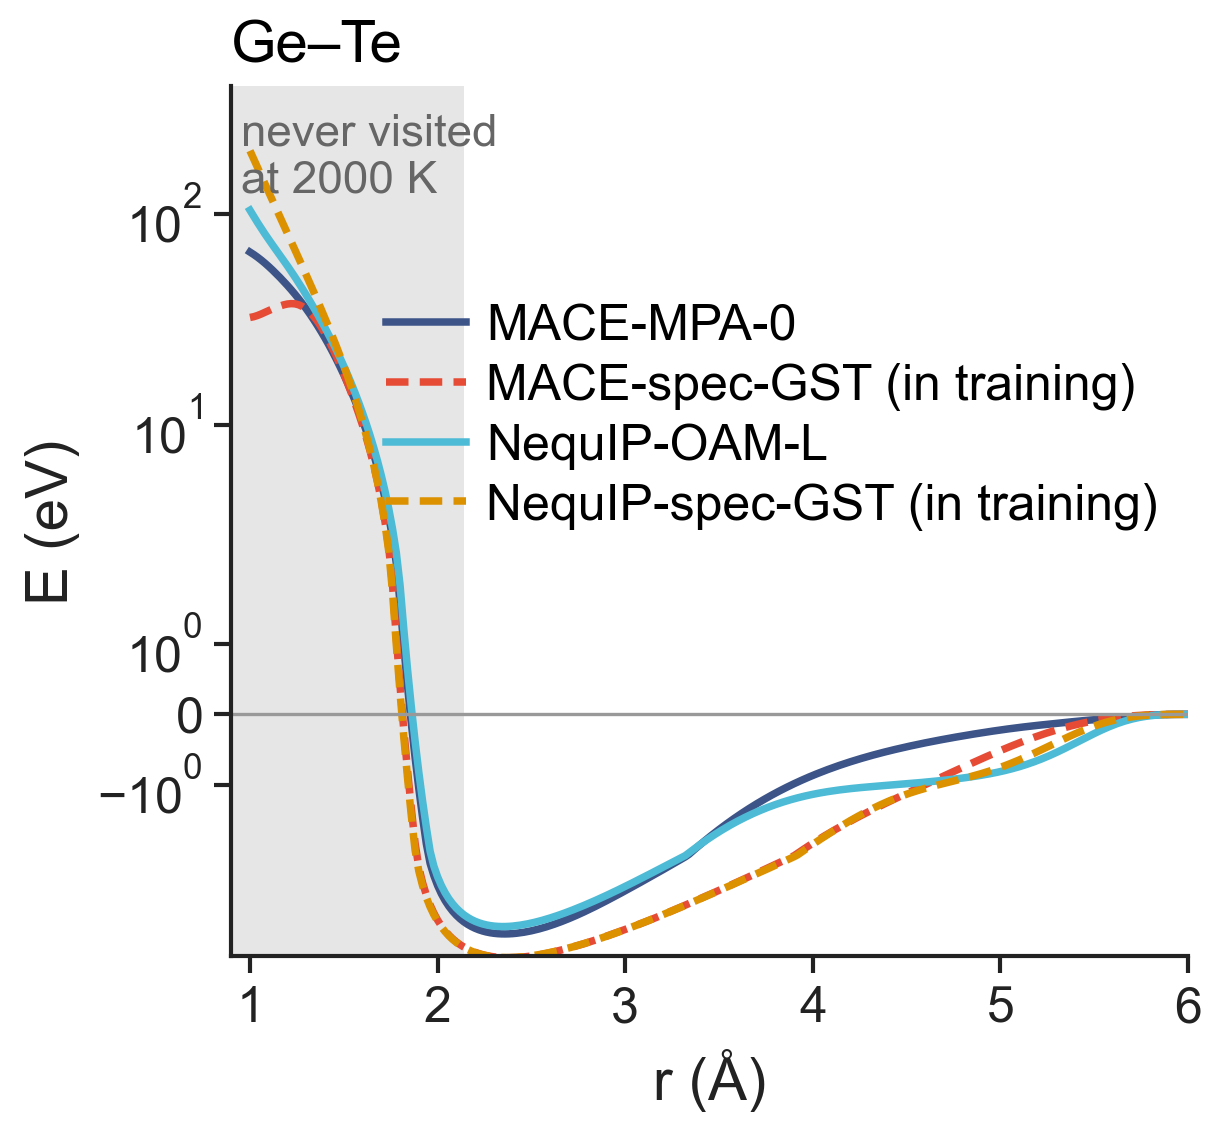

In [6]:
# ---------------- 本面板配色 ----------------
Ca_BAND = "#E6E6E6"
Ca_ZERO = "#999999"
# --------------------------------------------
def pec_panel(fig, spec, pair, legend):
    ax = fig.add_subplot(spec)
    ax.axvspan(0.9, DMIN, color=Ca_BAND, lw=0, zorder=0)
    ax.text(0.95, 300, "never visited\nat 2000 K", fontsize=FS_ANNOT - 0.5, va="top", color="#666666")
    for k in FOCUS:
        c = (PEC.get(k) or {}).get(pair)
        if c is None: continue
        dirty = f"L1.pec.{pair}" in contaminated(k)
        ax.plot(c["r"], c["energy"], color=col(k), lw=0.9, ls=(0, (3, 1.5)) if dirty else "-",
                label=lab(k) + (" (in training)" if dirty else ""))
    ax.axhline(0, color=Ca_ZERO, lw=0.4)
    ax.set_xlim(0.9, 6.0); ax.set_yscale("symlog", linthresh=2.0, linscale=0.6); ax.set_ylim(-6, 400)
    ax.set_xlabel("r (Å)"); ax.set_ylabel("E (eV)")
    ax.set_title(pair.replace("-", "–"), loc="left")
    if legend: ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.62), fontsize=FS_LEGEND)
    return ax
def draw_a(fig, spec):
    return pec_panel(fig, spec, "Ge-Te", True)
panel_run("a", draw_a)

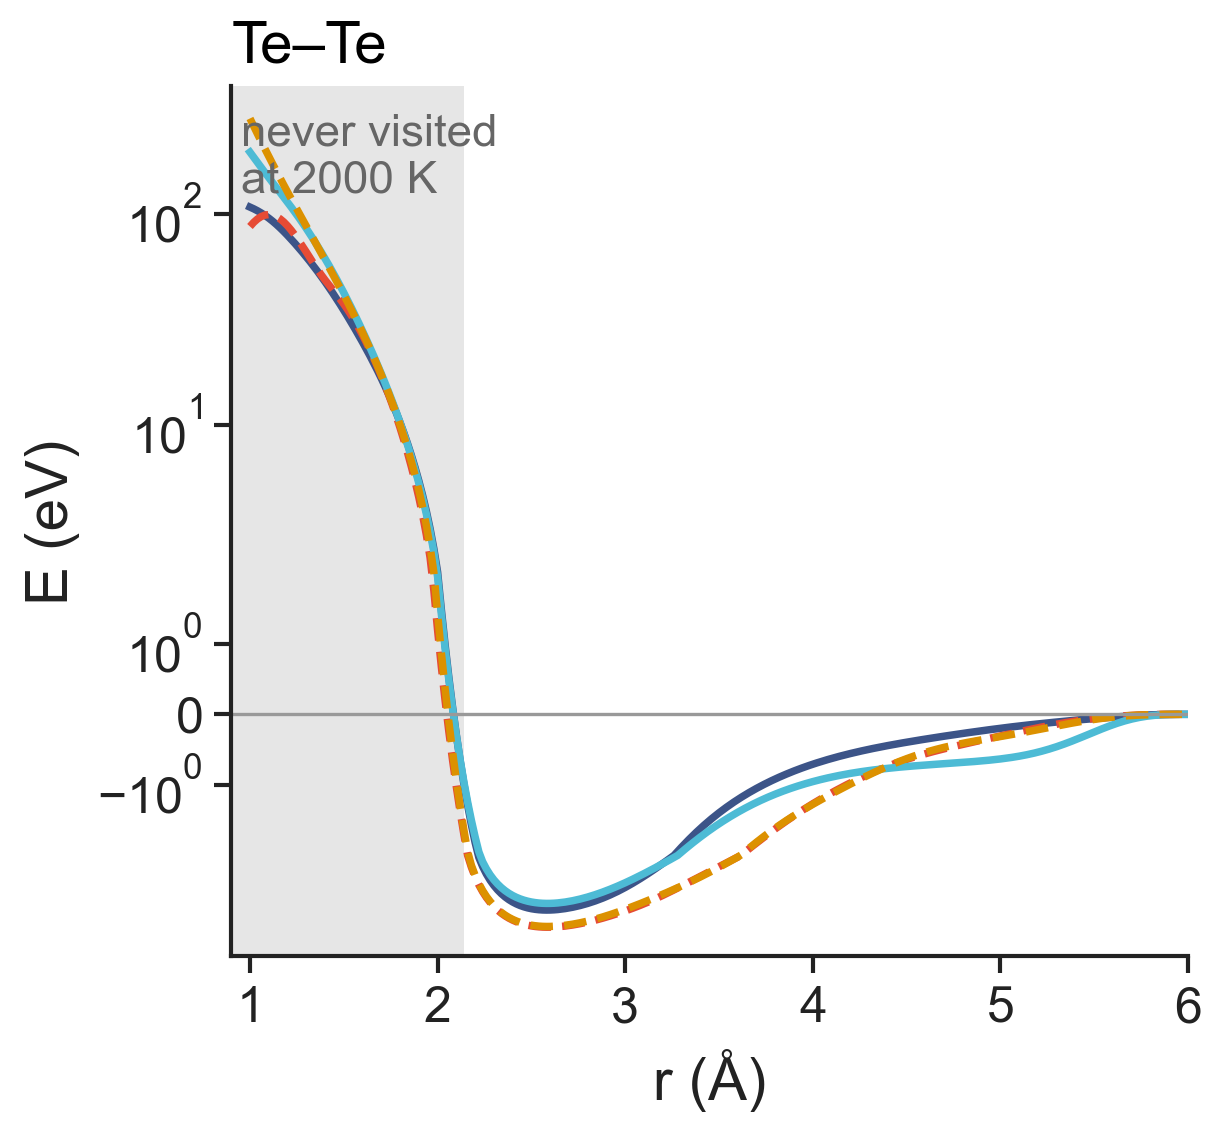

In [7]:
def draw_b(fig, spec):
    return pec_panel(fig, spec, "Te-Te", False)
panel_run("b", draw_b)

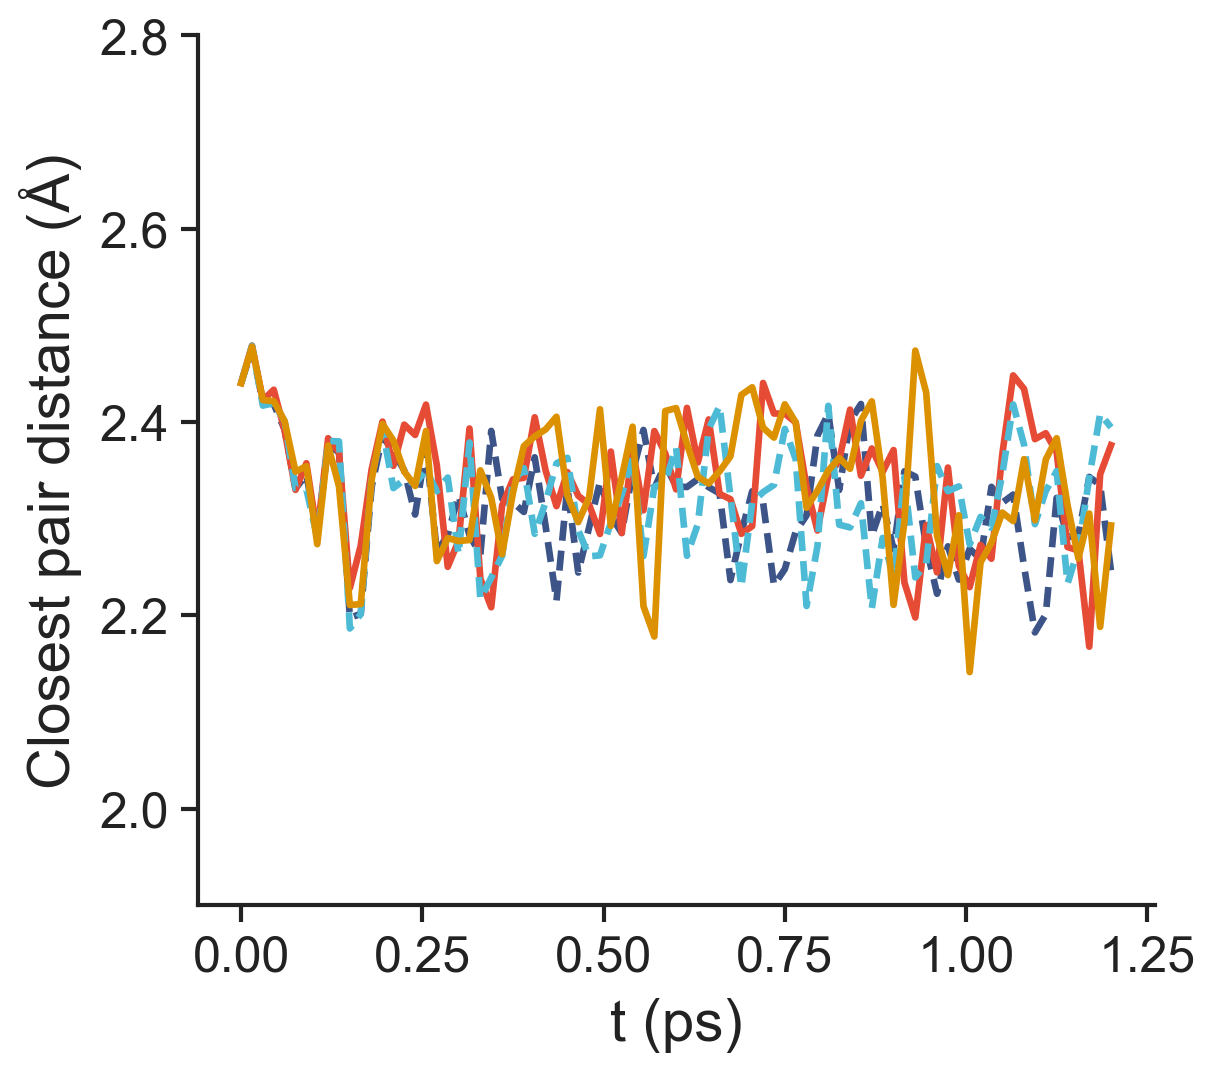

In [8]:
# ---------------- 本面板配色：沿用 style.MODELS ----------------
def draw_c(fig, spec):
    ax = fig.add_subplot(spec)
    for k in FOCUS:
        z = npz(k, "l1_stability_2000K.npz")
        ls = "-" if MODELS[k][3] == "specialised" else (0, (3, 1.5))
        ax.plot(z["time_fs"] / 1000, z["min_distance"], color=col(k), lw=0.8, ls=ls, label=lab(k))
    ax.set_xlabel("t (ps)"); ax.set_ylabel("Closest pair distance (Å)")
    ax.set_ylim(1.9, 2.8)
    return ax
panel_run("c", draw_c)

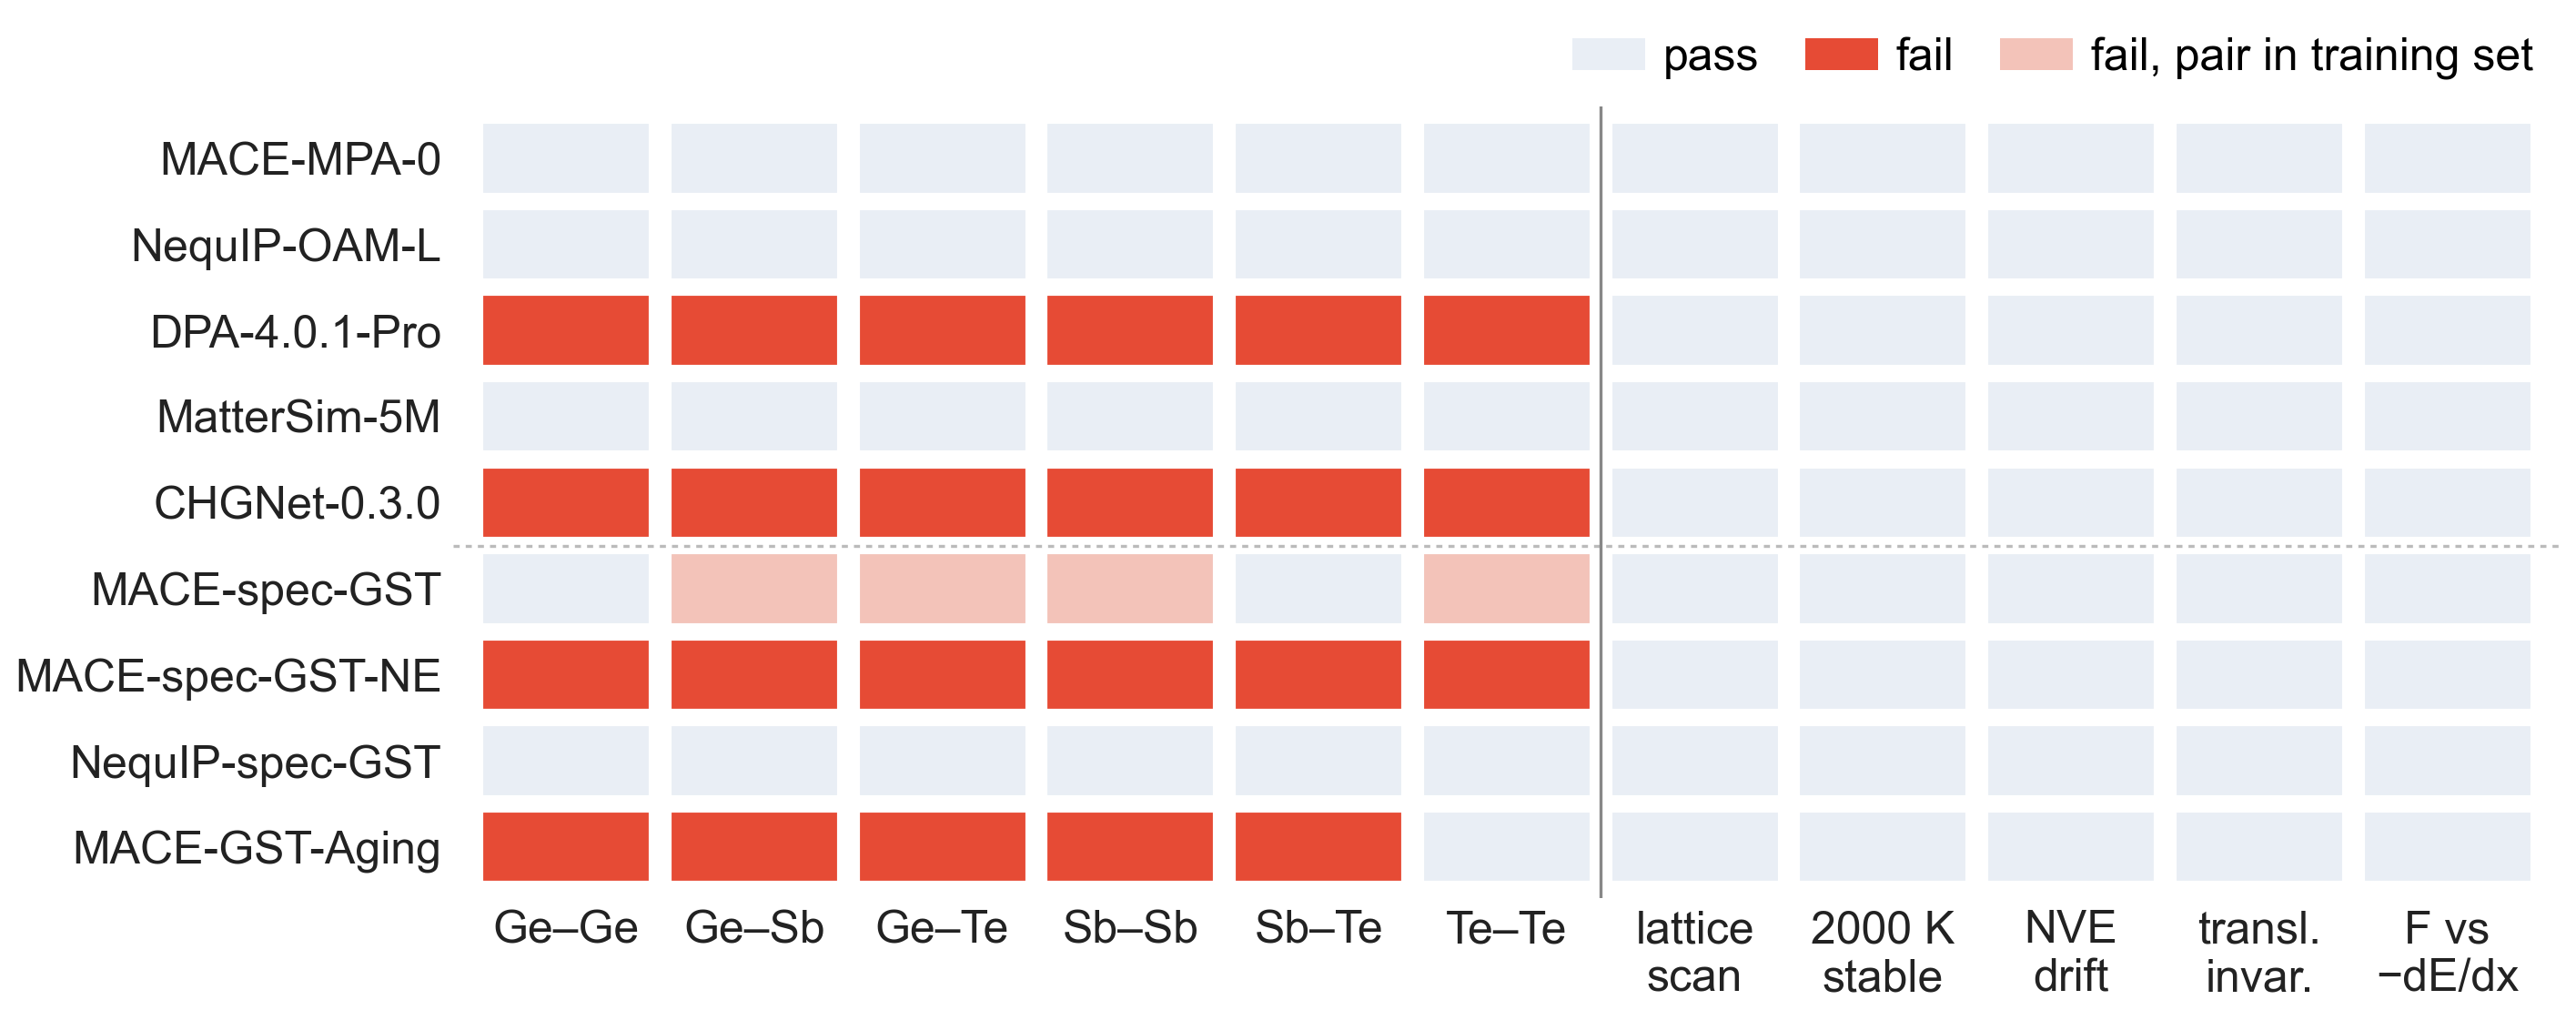

In [9]:
# ---------------- 本面板配色 ----------------
Cd_PASS, Cd_FAIL, Cd_DIRTY = "#E9EEF5", "#E64B35", "#F3C3B9"
Cd_EDGE = "#FFFFFF"
COLS = [f"L1.pec.{p}" for p in ["Ge-Ge", "Ge-Sb", "Ge-Te", "Sb-Sb", "Sb-Te", "Te-Te"]] + [
        "L1.lattice_scan_smoothness", "L1.stability_2000K.completed", "L1.nve_drift.dt=3fs",
        "L1.translation_invariance", "L1.force_vs_dE_dx"]
COL_NAMES = ["Ge–Ge", "Ge–Sb", "Ge–Te", "Sb–Sb", "Sb–Te", "Te–Te", "lattice\nscan", "2000 K\nstable", "NVE\ndrift",
             "transl.\ninvar.", "F vs\n−dE/dx"]
# --------------------------------------------
def draw_d(fig, spec):
    ax = fig.add_subplot(spec)
    y = model_rows(ax, True)
    from matplotlib.patches import Rectangle, Patch
    for k in SHOWCASE:
        failed = set(gate_failed(k)); dirty = contaminated(k)
        for j, m in enumerate(COLS):
            fc = (Cd_DIRTY if m in dirty else Cd_FAIL) if m in failed else Cd_PASS
            ax.add_patch(Rectangle((j - 0.45, y[k] - 0.42), 0.9, 0.84, facecolor=fc, edgecolor=Cd_EDGE, lw=0.5))
    ax.set_xlim(-0.6, len(COLS) - 0.4)
    ax.set_xticks(range(len(COLS))); ax.set_xticklabels(COL_NAMES)
    ax.tick_params(axis="x", length=0)
    for s in ("bottom", "left"): ax.spines[s].set_visible(False)
    ax.axvline(5.5, color="#888888", lw=0.4)
    ax.legend(handles=[Patch(fc=Cd_PASS, label="pass"), Patch(fc=Cd_FAIL, label="fail"),
                       Patch(fc=Cd_DIRTY, label="fail, pair in training set")],
              loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=3)
    return ax
panel_run("d", draw_d)

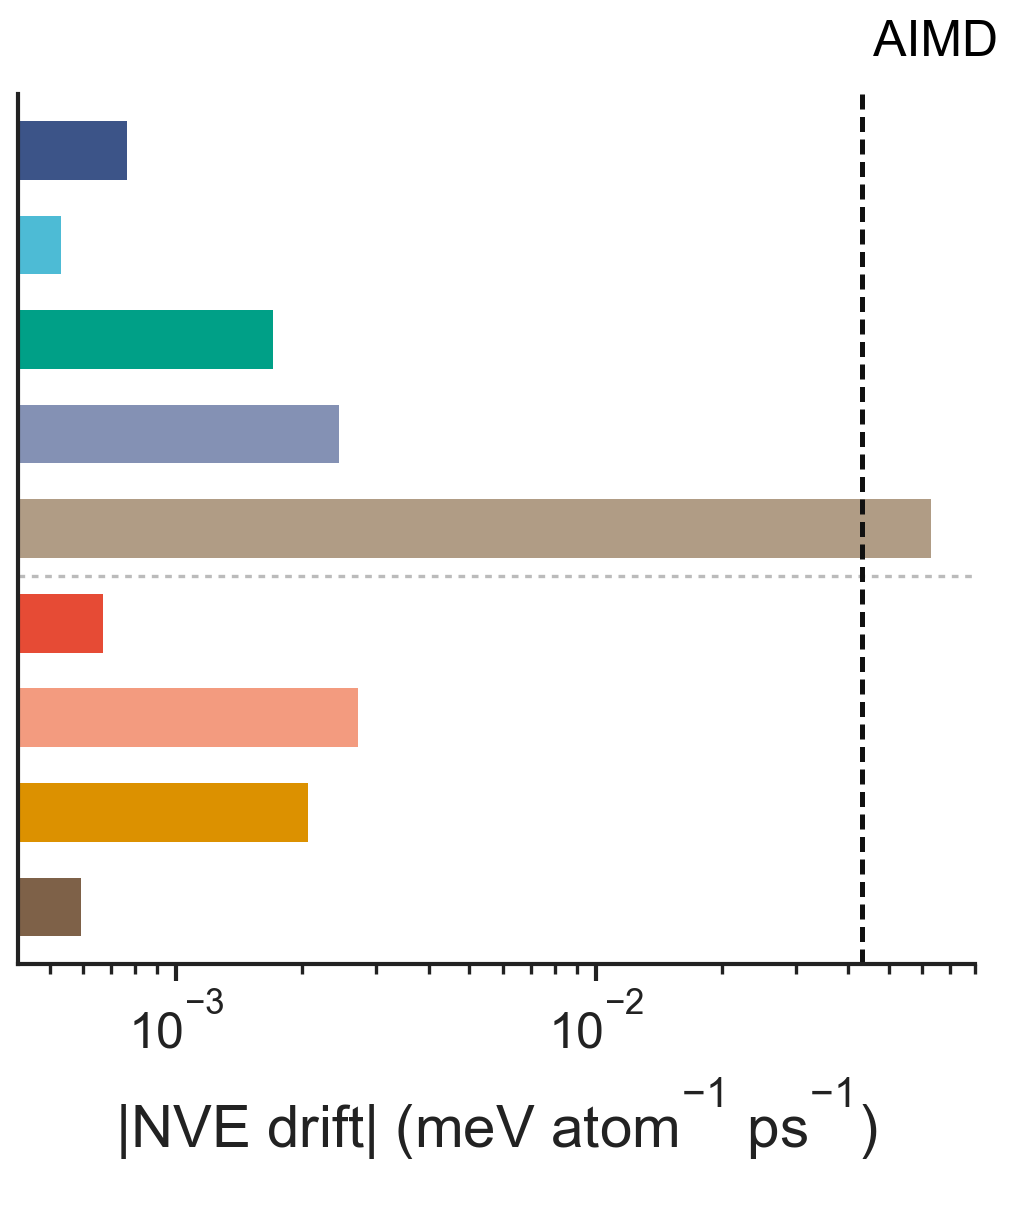

In [10]:
# ---------------- 本面板配色 ----------------
Ce_REF = "#111111"
# --------------------------------------------
def draw_e(fig, spec):
    ax = fig.add_subplot(spec)
    y = model_rows(ax, False)
    ref = None
    for k in SHOWCASE:
        r = L1[k]["L1.nve_drift.dt=3fs"]
        ax.barh(y[k], abs(r["value"]), height=0.62, color=col(k), lw=0)
        ref = r["extra"].get("aimd_reference_drift_meV_per_atom_per_ps", ref)
    ax.set_xscale("log")
    if ref:
        ax.axvline(ref, color=Ce_REF, lw=0.6, ls=(0, (3, 1.5)))
        ax.text(ref, -0.9, " AIMD", fontsize=FS_ANNOT, va="bottom")
    ax.set_xlabel("|NVE drift| (meV atom$^{-1}$ ps$^{-1}$)")
    return ax
panel_run("e", draw_e)

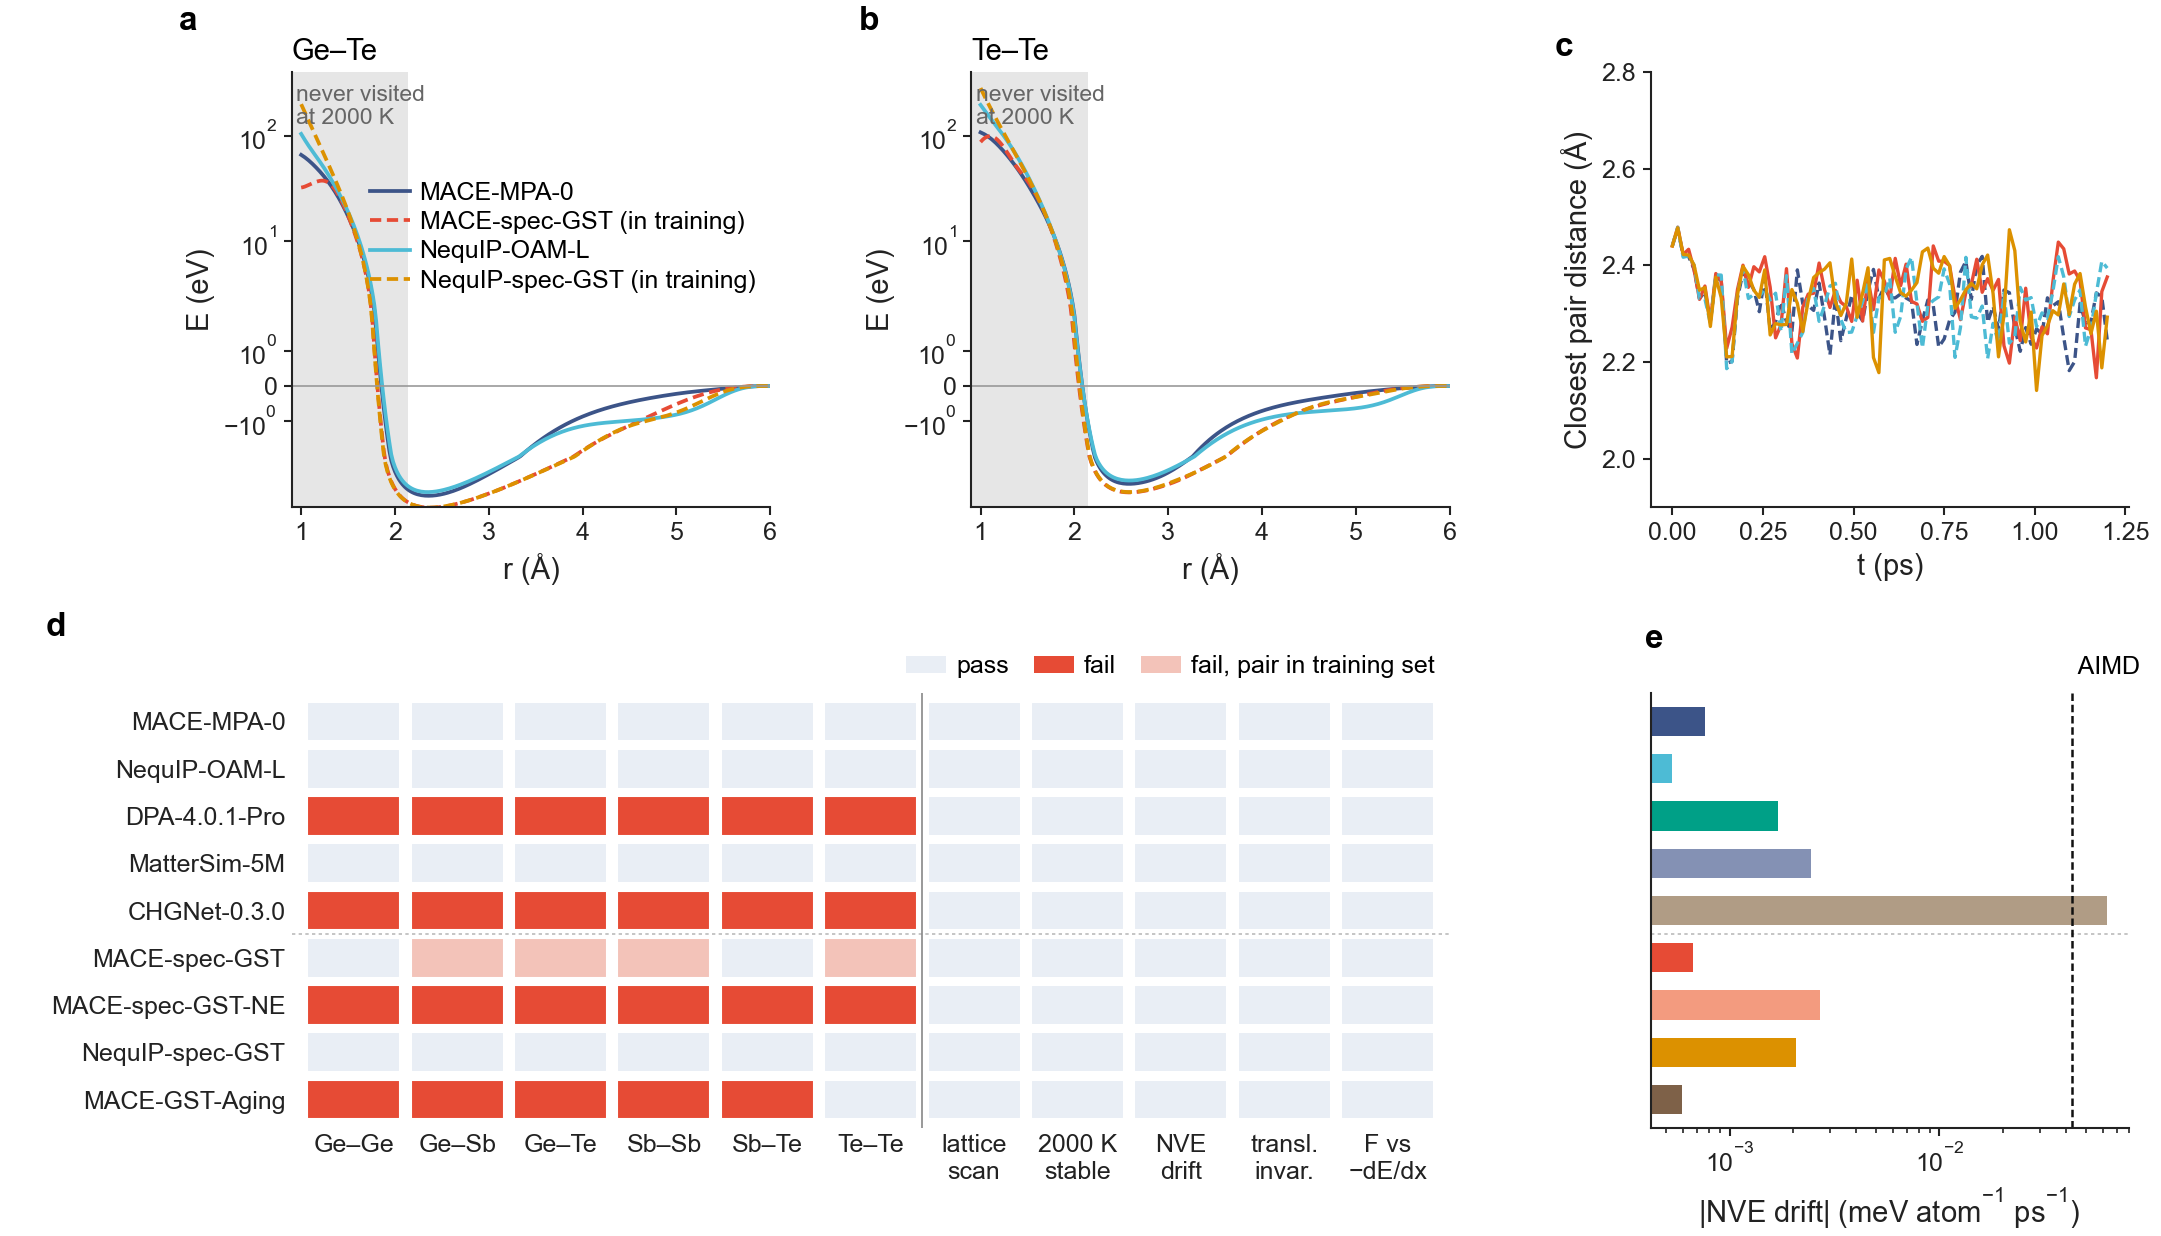

In [11]:
fig, slots = make_layout()
DRAW = {l: globals()[f"draw_{l}"] for l in LETTERS}
main_axes = {}
for l in LETTERS:
    n0 = len(fig.axes)
    ax = DRAW[l](fig, slots[l])
    main_axes[l] = ax
for l in LETTERS:
    mark(fig, main_axes[l], l, FS_PANEL)
png = export(fig, "fig3_L1")
groups = {}
plt.close(fig)
display(NotebookImage(filename=str(png), width=900))